1. **Бизнес-постановка задачи**

**Цель**: Создать систему автоматической фильтрации SMS-сообщений, которая классифицирует входящие тексты как «спам» (нежелательные рассылки, мошеннические схемы, реклама) или «ham» (легитимные сообщения от реальных людей и сервисов).

**Бизнес-ценность**: Операторы мобильной связи и платформы обмена сообщениями несут репутационные и финансовые потери из-за спама. Пользователи жалуются на нежелательные рассылки, а мошеннические SMS наносят прямой ущерб. Автоматический фильтр позволяет блокировать нежелательный трафик до доставки абоненту, снижая количество жалоб и повышая доверие к каналу коммуникации. Система должна работать с минимальной задержкой и обладать интерпретируемостью, чтобы в спорных случаях можно было объяснить причину блокировки.

    Постановка ML-задачи

**Тип задачи**: Бинарная классификация текстов.

**Вход**: Текстовое содержимое SMS-сообщения (последовательность слов/символов на английском языке).

**Выход**: Метка класса y ∈ {spam, ham}, где spam = 1, ham = 0.

Формальная постановка: Дано множество размеченных примеров D = {(x_i, y_i)}_{i=1}^{N}, где x_i — текст i-го сообщения, y_i ∈ {0, 1} — целевая метка. Требуется построить функцию f: X → Y, минимизирующую ошибку классификации на отложенной выборке, с особым акцентом на минимизацию ложноположительных срабатываний (ham → spam), поскольку блокировка легитимного сообщения воспринимается пользователем как критическая ошибка.

    Набор данных

**Источник**: UCI Machine Learning Repository — SMS Spam Collection v.1 .

Характеристики набора:

Объём: 5 574 реальных SMS-сообщения на английском языке.

Разметка: Бинарная — ham (легитимные) и spam (нежелательные).

Структура: Два поля — текст сообщения (sms) и метка класса (label) .

Достаточность для решения задачи: Набор содержит короткие типичные SMS и характерные спам-паттерны (ссылки, призывы к действию, обещания выигрыша). Существующие исследования на этом наборе достигают accuracy в диапазоне 97–99% с использованием классических ML-моделей , что подтверждает достаточность данных для построения работоспособного классификатора.

2. **Метрика качества и её обоснование**

**Выбранная метрика**: Precision (точность) для класса spam в качестве основной, с Recall и F1-мерой как дополнительными для мониторинга.

**Обоснование**: В задаче фильтрации спама ложноположительное срабатывание (легитимное сообщение ошибочно помечено как спам) обходится значительно дороже, чем пропуск спама: пользователь может не получить важное уведомление (код подтверждения, сообщение от близкого). Поэтому приоритет отдаётся высокой precision - из всех сообщений, которые модель назвала спамом, максимальная доля должна быть действительно спамом. Recall также важен для понимания полноты фильтрации, но он оптимизируется после достижения приемлемого уровня precision. F1 (гармоническое среднее между точностью и полнотой) используется как агрегированный показатель для сравнения моделей в ходе экспериментов.

3. **EDA**


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
!git clone https://github.com/quLyash/urfu_da_hw_morgun.git

Cloning into 'urfu_da_hw_morgun'...
remote: Enumerating objects: 22, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 22 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (22/22), 211.77 KiB | 21.18 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [10]:
%cd urfu_da_hw_morgun/HW_1
import pandas as pd
df = pd.read_csv('SMSSpamCollection', sep='\t', names=['label', 'sms'])
print(df.shape)

/content/urfu_da_hw_morgun/HW_1
(5572, 2)


In [11]:
# Базовая информация
print(df.info())
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   sms     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64


На одно спам-сообщение приходится примерно 6–7 легитимных. Это типичная ситуация для реального спам-трафика. Дисбаланс означает, что метрика accuracy может вводить в заблуждение (модель, всегда предсказывающая ham, даст ~86.6% accuracy, но будет бесполезна). Поэтому при обучении необходимо использовать class_weight='balanced' или стратегии ресемплинга, а оценку производить по precision/recall/F1.

In [13]:
# Длина сообщений
df['length'] = df['sms'].apply(len)
print(df.groupby('label')['length'].describe())

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.482487  58.440652   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.670683  28.873603  13.0  133.0  149.0  157.0  223.0


Спам-сообщения в среднем вдвое длиннее легитимных. Это объясняется тем, что спам часто содержит рекламные тексты, ссылки и призывы к действию, тогда как ham — короткие бытовые сообщения. Признак длины текста может быть полезен как дополнительная инженерия признаков.

/tmp/ipykernel_1389/3764760497.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette=['#2ecc71', '#e74c3c'])


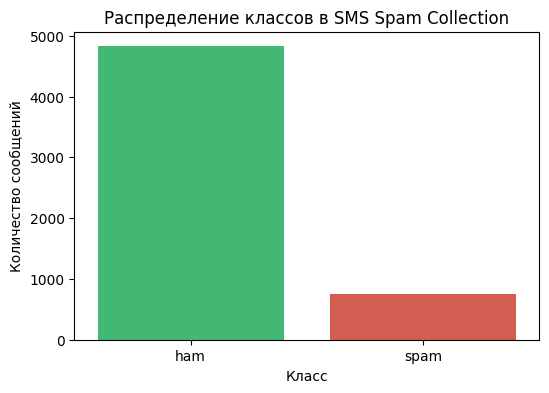

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', palette=['#2ecc71', '#e74c3c'])
plt.title('Распределение классов в SMS Spam Collection')
plt.xlabel('Класс')
plt.ylabel('Количество сообщений')
plt.show()

Визуализация наглядно демонстрирует дисбаланс. При разделении на train/test необходимо использовать стратификацию (stratify=y), чтобы сохранить пропорцию классов в обеих выборках. Иначе тестовая выборка может случайно оказаться смещённой, и оценка качества будет нестабильной.

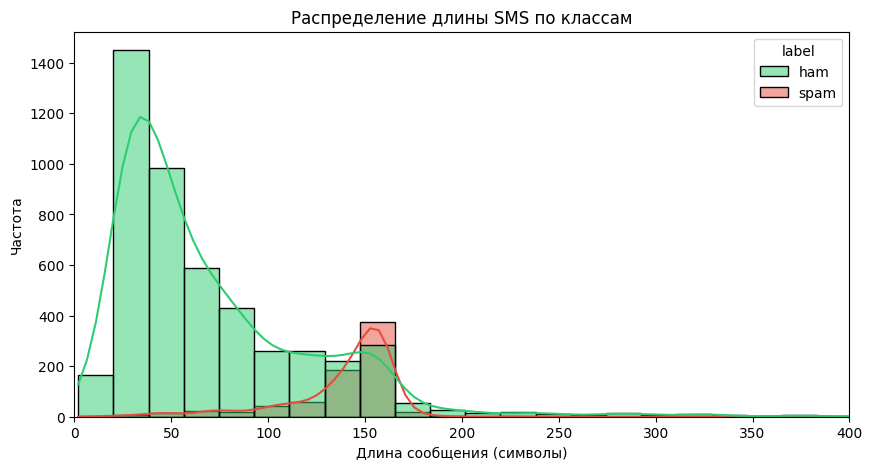

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='length', hue='label', bins=50, kde=True, palette=['#2ecc71', '#e74c3c'])
plt.title('Распределение длины SMS по классам')
plt.xlabel('Длина сообщения (символы)')
plt.ylabel('Частота')
plt.xlim(0, 400)
plt.show()

Гистограмма показывает, что ham-сообщения концентрируются в области коротких текстов (до 100 символов), тогда как спам имеет более широкое распределение со сдвигом вправо. Однако есть и короткие спам-сообщения. Это означает, что длина — полезный, но недостаточный признак; основной сигнал должен извлекаться из содержания текста.

In [18]:
from collections import Counter
import re

def get_top_words(texts, n=15):
    words = ' '.join(texts).lower()
    words = re.findall(r'\b[a-z]+\b', words)
    return Counter(words).most_common(n)

print("Топ слов в SPAM:")
print(get_top_words(df[df['label'] == 'spam']['sms']))
print("\nТоп слов в HAM:")
print(get_top_words(df[df['label'] == 'ham']['sms']))

Топ слов в SPAM:
[('to', 691), ('a', 380), ('call', 355), ('you', 297), ('your', 264), ('free', 224), ('the', 206), ('for', 204), ('now', 199), ('or', 188), ('u', 174), ('txt', 163), ('is', 158), ('on', 145), ('ur', 144)]

Топ слов в HAM:
[('i', 2960), ('you', 1948), ('to', 1562), ('the', 1133), ('a', 1070), ('u', 1033), ('and', 858), ('in', 823), ('me', 777), ('my', 754), ('is', 739), ('it', 718), ('that', 560), ('of', 526), ('for', 507)]


В SPAM на высоких позициях находятся слова-триггеры: call, free, now, txt. Также часто встречаются сокращения u и ur. Это типичная лексика маркетинговых рассылок, призывов к действию и мошеннических схем («позвоните сейчас», «бесплатно», «отправьте SMS»).

В HAM преобладают личные местоимения (i, you, me, my) и служебные части речи (and, in, that). Это отражает естественную разговорную речь при общении между людьми.

**Выводы по EDA:**

1. Дисбаланс классов (~86.6% / 13.4%) требует стратифицированного разбиения и учёта весов классов при обучении.

2. Длина сообщения — информативный, но не решающий признак. Основная работа должна вестись с текстом.

3. Необходимо будет привести текст к нижнему регистру, удалить или заменить URL-адреса (в спаме они часты, но конкретный URL не важен — важен сам факт наличия ссылки), удалить пунктуацию и специальные символы. Для SMS с их неформальной орфографией («u», «2», «pls») следует рассмотреть нормализацию сокращений.

4. Векторизация: TF-IDF с ограничением по минимальной частоте документа (min_df=2–3) для отсечения редких опечаток и шума. Биграммы повысят качество за счёт захвата устойчивых спам-фраз.

5. Проверить наличие дубликатов сообщений в наборе. Необходимо проверить df['sms'].duplicated().sum() и при обнаружении — удалить дубликаты до разбиения на train/test, чтобы избежать утечки данных.